In [1]:
import pickle, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

In [2]:
# ── Paths ──
NET_DIR  = r'E:\Claude\euclid-analysis\output\networks'
OUT_DIR  = r'E:\Claude\euclid-analysis\output\initial_analysis'
REF_DIR  = r'E:\Claude\euclid-analysis\data\reference'

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

# ── Load networks ──
net_paths = {
    'Human':  f'{NET_DIR}/Human_Citation_Network.pkl',
    'Opus-A': f'{NET_DIR}/RunA_AI_Citation_Network_Final.pkl',
    'Opus-B': f'{NET_DIR}/RunB_AI_Citation_Network_Final.pkl',
    'Opus-C': f'{NET_DIR}/RunC_AI_Citation_Network_Final.pkl',
    'Fable':  f'{NET_DIR}/Fable_AI_Citation_Network_Final.pkl',
    'GPT-6':  f'{NET_DIR}/GPT_AI_Citation_Network_Final.pkl',
}
graphs = {}
for name, path in net_paths.items():
    with open(path, 'rb') as f:
        graphs[name] = pickle.load(f)

# ── Load word counts ──
df_wc = pd.read_csv(f'{OUT_DIR}/ai_proof_wordcounts_all_models.csv', dtype={'prop': str})

# Human word counts from Heath
df_heath = pd.read_excel(f'{REF_DIR}/Euclid_Heath_Proofs.xlsx', dtype={'ID': str})
df_heath = df_heath[df_heath['ID'].str.match(r'^\d+\.\d+$', na=False)]
df_heath['words'] = df_heath['Proof'].str.split().str.len()
df_heath = df_heath.rename(columns={'ID': 'prop'})
df_heath['model'] = 'Human'
df_heath['run'] = 'H'
df_heath['book'] = df_heath['prop'].str.split('.').str[0].astype(int)
df_wc_all = pd.concat([df_wc, df_heath[['model', 'run', 'prop', 'book', 'words']]], ignore_index=True)

# ── Load timing ──
df_tm = pd.read_csv(f'{OUT_DIR}/proof_timings_all_models.csv', dtype={'Proposition': str})

# ── CCDF helper ──
def ccdf(data):
    data = np.sort(data)
    mask = data > 0
    data = data[mask]
    n = len(data)
    return data, np.arange(n, 0, -1) / n

# ── Colors & line styles ──
style = {
    'Human':  dict(color='#333333', lw=2.0, ls='-'),
    'Opus-A': dict(color='#1f77b4', lw=1.2, ls='-'),
    'Opus-B': dict(color='#6baed6', lw=1.2, ls='--'),
    'Opus-C': dict(color='#9ecae1', lw=1.2, ls=':'),
    'Fable':  dict(color='#e6550d', lw=1.5, ls='-'),
    'GPT-6':  dict(color='#31a354', lw=1.5, ls='-'),
}
draw_order = ['Human', 'Opus-A', 'Opus-B', 'Opus-C', 'Fable', 'GPT-6']

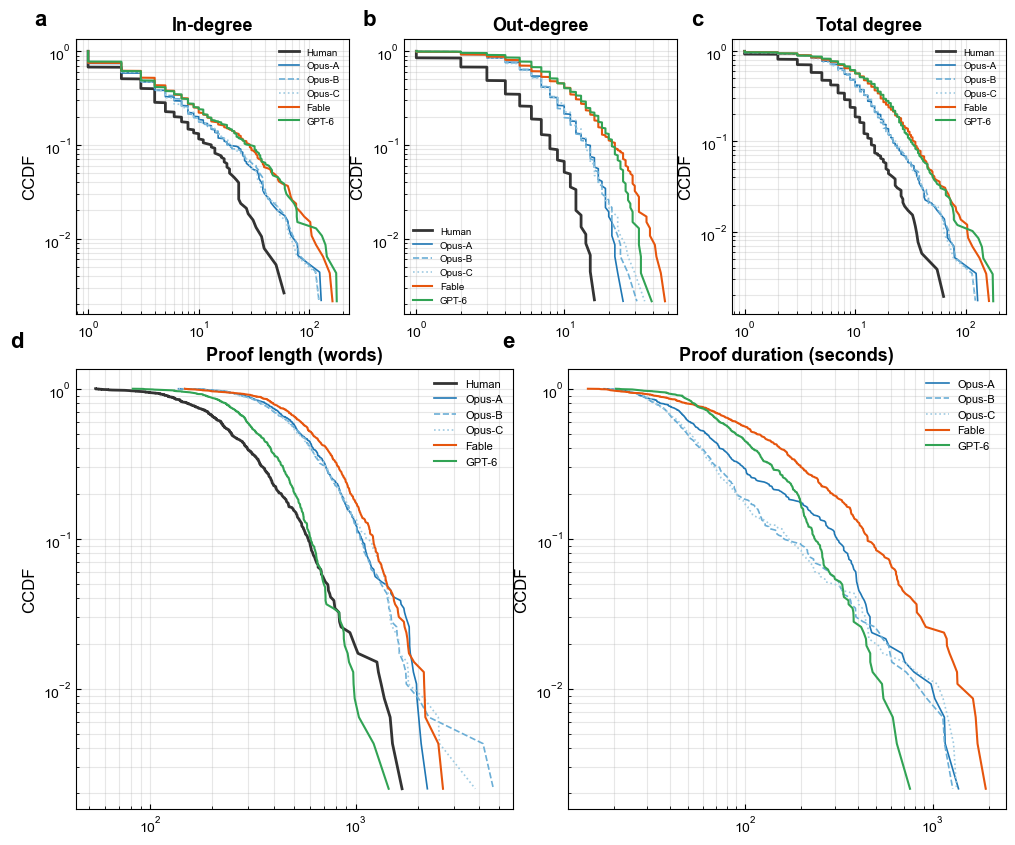

In [3]:
# ── Figure ──
fig = plt.figure(figsize=(12, 10))
gs = GridSpec(5, 6, hspace=0.5, wspace=0.5)

ax_in  = fig.add_subplot(gs[0:2, 0:2])
ax_out = fig.add_subplot(gs[0:2, 2:4])
ax_tot = fig.add_subplot(gs[0:2, 4:6])
ax_wc  = fig.add_subplot(gs[2:5, 0:3])
ax_tm  = fig.add_subplot(gs[2:5, 3:6])

panels = [ax_in, ax_out, ax_tot, ax_wc, ax_tm]

# ── Row 1: Degree distributions ──
for name in draw_order:
    G = graphs[name]
    in_deg  = np.array([d for _, d in G.in_degree()])
    out_deg = np.array([d for _, d in G.out_degree()])
    tot_deg = in_deg + out_deg

    x, y = ccdf(in_deg);  ax_in.plot(x, y,  label=name, **style[name])
    x, y = ccdf(out_deg); ax_out.plot(x, y, label=name, **style[name])
    x, y = ccdf(tot_deg); ax_tot.plot(x, y, label=name, **style[name])

for ax, title in [(ax_in, 'In-degree'), (ax_out, 'Out-degree'), (ax_tot, 'Total degree')]:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('CCDF', fontsize=12)
    ax.tick_params(labelsize=10)
    ax.legend(fontsize=7, frameon=False)
    ax.grid(alpha=0.3, which='both')

# ── Row 2 left: Word count CCDF (5 AI + Human) ──
wc_models = {
    'Human':  df_wc_all[df_wc_all['model'] == 'Human']['words'].values,
    'Opus-A': df_wc_all[(df_wc_all['model'] == 'Opus') & (df_wc_all['run'] == 'A')]['words'].values,
    'Opus-B': df_wc_all[(df_wc_all['model'] == 'Opus') & (df_wc_all['run'] == 'B')]['words'].values,
    'Opus-C': df_wc_all[(df_wc_all['model'] == 'Opus') & (df_wc_all['run'] == 'C')]['words'].values,
    'Fable':  df_wc_all[df_wc_all['model'] == 'Fable']['words'].values,
    'GPT-6':  df_wc_all[df_wc_all['model'] == 'GPT-6']['words'].values,
}
for name in draw_order:
    x, y = ccdf(wc_models[name])
    ax_wc.plot(x, y, label=name, **style[name])

ax_wc.set_xscale('log')
ax_wc.set_yscale('log')
ax_wc.set_title('Proof length (words)', fontsize=13, fontweight='bold')
ax_wc.set_ylabel('CCDF', fontsize=12)
ax_wc.tick_params(labelsize=10)
ax_wc.legend(fontsize=8, frameon=False)
ax_wc.grid(alpha=0.3, which='both')

# ── Row 2 right: Timing CCDF (5 AI only) ──
tm_map = {
    'Opus-A': df_tm[df_tm['model'] == 'Opus-A']['Duration_s'].values,
    'Opus-B': df_tm[df_tm['model'] == 'Opus-B']['Duration_s'].values,
    'Opus-C': df_tm[df_tm['model'] == 'Opus-C']['Duration_s'].values,
    'Fable':  df_tm[df_tm['model'] == 'Fable']['Duration_s'].values,
    'GPT-6':  df_tm[df_tm['model'] == 'GPT-6']['Duration_s'].values,
}
for name in draw_order:
    if name == 'Human':
        continue
    x, y = ccdf(tm_map[name])
    ax_tm.plot(x, y, label=name, **style[name])

ax_tm.set_xscale('log')
ax_tm.set_yscale('log')
ax_tm.set_title('Proof duration (seconds)', fontsize=13, fontweight='bold')
ax_tm.set_ylabel('CCDF', fontsize=12)
ax_tm.tick_params(labelsize=10)
ax_tm.legend(fontsize=8, frameon=False)
ax_tm.grid(alpha=0.3, which='both')

# ── Panel labels ──
for ax, lab in zip(panels, list('abcde')):
    ax.text(-0.15, 1.05, lab, transform=ax.transAxes,
            fontsize=16, fontweight='bold')

#plt.savefig('E:/AI证明与人类证明的差异/Opus4.6正式实验/分析结果/figure2.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
import pickle, numpy as np, pandas as pd, matplotlib.pyplot as plt
import networkx as nx
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

In [24]:
# ── Paths ──
NET_DIR  = r'E:\Claude\euclid-analysis\output\networks'
OUT_DIR  = r'E:\Claude\euclid-analysis\output\initial_analysis'
REF_DIR  = r'E:\Claude\euclid-analysis\data\reference'

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

# ── Load networks ──
net_paths = {
    'Human':  f'{NET_DIR}/Human_Citation_Network.pkl',
    'Opus-A': f'{NET_DIR}/RunA_AI_Citation_Network_Final.pkl',
    'Opus-B': f'{NET_DIR}/RunB_AI_Citation_Network_Final.pkl',
    'Opus-C': f'{NET_DIR}/RunC_AI_Citation_Network_Final.pkl',
    'Fable':  f'{NET_DIR}/Fable_AI_Citation_Network_Final.pkl',
    'GPT-6':  f'{NET_DIR}/GPT_AI_Citation_Network_Final.pkl',
}
draw_order = ['Human', 'Opus-A', 'Opus-B', 'Opus-C', 'Fable', 'GPT-6']

graphs = {}
for name, path in net_paths.items():
    with open(path, 'rb') as f:
        graphs[name] = pickle.load(f)

# ── Load word counts ──
df_wc = pd.read_csv(f'{OUT_DIR}/ai_proof_wordcounts_all_models.csv', dtype={'prop': str})
df_heath = pd.read_excel(f'{REF_DIR}/Euclid_Heath_Proofs.xlsx', dtype={'ID': str})
df_heath = df_heath[df_heath['ID'].str.match(r'^\d+\.\d+$', na=False)]
df_heath['words'] = df_heath['Proof'].str.split().str.len()
df_heath = df_heath.rename(columns={'ID': 'prop'})
df_heath['model'] = 'Human'
df_heath['run'] = 'H'
df_heath['book'] = df_heath['prop'].str.split('.').str[0].astype(int)
df_wc_all = pd.concat([df_wc, df_heath[['model', 'run', 'prop', 'book', 'words']]], ignore_index=True)

# ── Load timing ──
df_tm = pd.read_csv(f'{OUT_DIR}/proof_timings_all_models.csv', dtype={'Proposition': str})

# ── Compute topology metrics (undirected) ──
metrics_names = ['Nodes', 'Edges', 'Density', 'Avg degree',
                 'Avg shortest path', 'Avg clustering']
metrics_data = {}

for name in draw_order:
    G = graphs[name]
    U = G.to_undirected()
    n = U.number_of_nodes()
    e = U.number_of_edges()
    largest_cc = max(nx.connected_components(U), key=len)
    U_cc = U.subgraph(largest_cc)
    avg_sp = nx.average_shortest_path_length(U_cc)
    avg_cl = nx.average_clustering(U)
    avg_deg = sum(d for _, d in U.degree()) / n

    metrics_data[name] = {
        'Nodes': n,
        'Edges': e,
        'Density': nx.density(U),
        'Avg degree': avg_deg,
        'Avg shortest path': avg_sp,
        'Avg clustering': avg_cl,
    }

# ── CCDF helper ──
def ccdf(data):
    data = np.sort(data)
    mask = data > 0
    data = data[mask]
    n = len(data)
    return data, np.arange(n, 0, -1) / n

# ── Colors & line styles ──
style = {
    'Human':  dict(color='#333333', lw=2.0, ls='-'),
    'Opus-A': dict(color='#1f77b4', lw=1.2, ls='-'),
    'Opus-B': dict(color='#6baed6', lw=1.2, ls='--'),
    'Opus-C': dict(color='#9ecae1', lw=1.2, ls=':'),
    'Fable':  dict(color='#e6550d', lw=1.5, ls='-'),
    'GPT-6':  dict(color='#31a354', lw=1.5, ls='-'),
}
dot_colors = {k: v['color'] for k, v in style.items()}

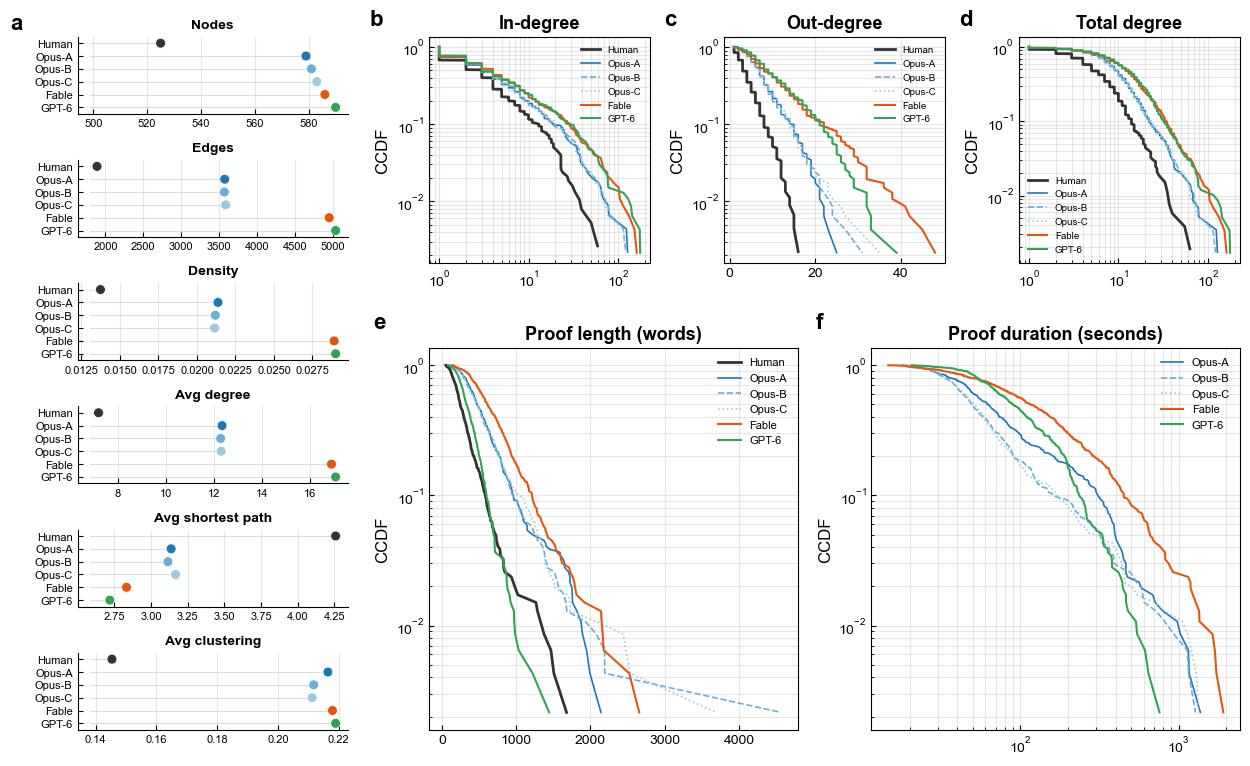

In [29]:
# ── Figure ──
fig = plt.figure(figsize=(15, 9))
gs = GridSpec(1, 2, width_ratios=[2, 6], wspace=0.15)

# Left: 6 dot plots, independent spacing
gs_left = GridSpecFromSubplotSpec(6, 1, subplot_spec=gs[0], hspace=0.6)
dot_axes = [fig.add_subplot(gs_left[i]) for i in range(6)]

# Right: degree/wordcount/timing panels, independent spacing
gs_right = GridSpecFromSubplotSpec(5, 6, subplot_spec=gs[1], hspace=1.2, wspace=1)

ax_in  = fig.add_subplot(gs_right[0:2, 0:2])
ax_out = fig.add_subplot(gs_right[0:2, 2:4])
ax_tot = fig.add_subplot(gs_right[0:2, 4:6])
ax_wc  = fig.add_subplot(gs_right[2:5, 0:3])
ax_tm  = fig.add_subplot(gs_right[2:5, 3:6])

# ── Left: Dot plots ──
y_pos = np.arange(len(draw_order))

for i, metric in enumerate(metrics_names):
    ax = dot_axes[i]
    vals = [metrics_data[name][metric] for name in draw_order]
    colors_list = [dot_colors[name] for name in draw_order]

    ax.scatter(vals, y_pos, c=colors_list, s=50, zorder=3, edgecolors='white', linewidths=0.5)
    for j, (v, name) in enumerate(zip(vals, draw_order)):
        ax.plot([min(vals) * 0.95, v], [j, j], color='#ddd', lw=0.8, zorder=1)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(draw_order, fontsize=8)
    ax.set_title(metric, fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', labelsize=8)
    ax.set_ylim(-0.5, len(draw_order) - 0.5)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

dot_axes[0].text(-0.25, 1.1, 'a', transform=dot_axes[0].transAxes,
                 fontsize=16, fontweight='bold')

# ── Row 1: Degree CCDF ──
for name in draw_order:
    G = graphs[name]
    in_deg  = np.array([d for _, d in G.in_degree()])
    out_deg = np.array([d for _, d in G.out_degree()])
    tot_deg = in_deg + out_deg

    x, y = ccdf(in_deg);  ax_in.plot(x, y,  label=name, **style[name])
    x, y = ccdf(out_deg); ax_out.plot(x, y, label=name, **style[name])
    x, y = ccdf(tot_deg); ax_tot.plot(x, y, label=name, **style[name])

for ax, title in [(ax_in, 'In-degree'), (ax_out, 'Out-degree'), (ax_tot, 'Total degree')]:
    if ax==ax_out:
        ax.set_yscale('log')
    else:
        ax.set_xscale('log')
        ax.set_yscale('log')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('CCDF', fontsize=12)
    ax.tick_params(labelsize=10)
    ax.legend(fontsize=7, frameon=False)
    ax.grid(alpha=0.3, which='both')

# ── Row 2 left: Word count CCDF ──
wc_models = {
    'Human':  df_wc_all[df_wc_all['model'] == 'Human']['words'].values,
    'Opus-A': df_wc_all[(df_wc_all['model'] == 'Opus') & (df_wc_all['run'] == 'A')]['words'].values,
    'Opus-B': df_wc_all[(df_wc_all['model'] == 'Opus') & (df_wc_all['run'] == 'B')]['words'].values,
    'Opus-C': df_wc_all[(df_wc_all['model'] == 'Opus') & (df_wc_all['run'] == 'C')]['words'].values,
    'Fable':  df_wc_all[df_wc_all['model'] == 'Fable']['words'].values,
    'GPT-6':  df_wc_all[df_wc_all['model'] == 'GPT-6']['words'].values,
}
for name in draw_order:
    x, y = ccdf(wc_models[name])
    ax_wc.plot(x, y, label=name, **style[name])

#ax_wc.set_xscale('log')
ax_wc.set_yscale('log')
ax_wc.set_title('Proof length (words)', fontsize=13, fontweight='bold')
ax_wc.set_ylabel('CCDF', fontsize=12)
ax_wc.tick_params(labelsize=10)
ax_wc.legend(fontsize=8, frameon=False)
ax_wc.grid(alpha=0.3, which='both')

# ── Row 2 right: Timing CCDF ──
tm_map = {
    'Opus-A': df_tm[df_tm['model'] == 'Opus-A']['Duration_s'].values,
    'Opus-B': df_tm[df_tm['model'] == 'Opus-B']['Duration_s'].values,
    'Opus-C': df_tm[df_tm['model'] == 'Opus-C']['Duration_s'].values,
    'Fable':  df_tm[df_tm['model'] == 'Fable']['Duration_s'].values,
    'GPT-6':  df_tm[df_tm['model'] == 'GPT-6']['Duration_s'].values,
}
for name in draw_order:
    if name == 'Human':
        continue
    x, y = ccdf(tm_map[name])
    ax_tm.plot(x, y, label=name, **style[name])

ax_tm.set_xscale('log')
ax_tm.set_yscale('log')
ax_tm.set_title('Proof duration (seconds)', fontsize=13, fontweight='bold')
ax_tm.set_ylabel('CCDF', fontsize=12)
ax_tm.tick_params(labelsize=10)
ax_tm.legend(fontsize=8, frameon=False)
ax_tm.grid(alpha=0.3, which='both')

# ── Panel labels (b–f) ──
right_panels = [ax_in, ax_out, ax_tot, ax_wc, ax_tm]
for ax, lab in zip(right_panels, list('bcdef')):
    x_offset = -0.27 if lab in ('b', 'c', 'd') else -0.15
    ax.text(x_offset, 1.05, lab, transform=ax.transAxes,
            fontsize=16, fontweight='bold')

#plt.savefig('E:/AI证明与人类证明的差异/Opus4.6正式实验/分析结果/figure2.pdf', dpi=300, bbox_inches='tight')
plt.show()